# Sequential Data and Recurrent Neural Networks

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Part 1: Data preprocessing

In [35]:
from scipy.integrate import solve_ivp

def lorenz(t, x, sigma=10., beta=8./3., rho=28):
    return [
        sigma * (x[1] - x[0]),
        x[0] * (rho - x[2]) - x[1],
        x[0] * x[1]  - beta * x[2]
    ]

def generate_lorenz(t_max=20, dt=0.02, x0=None, sigma=10., beta=8./3., rho=28):
    if x0 is None:
        x0 = -15 + 30 * np.random.uniform(size=3)
    t_eval = np.arange(0, t_max, dt)
    func = lambda t, x: lorenz(t, x, sigma=sigma, beta=beta, rho=rho)
    x = solve_ivp(func, (t_eval[0], t_eval[-1]), x0, t_eval=t_eval, rtol=1e-8, atol=1e-8).y.T
    return x[:, (0, 2)]

(1000, 2)


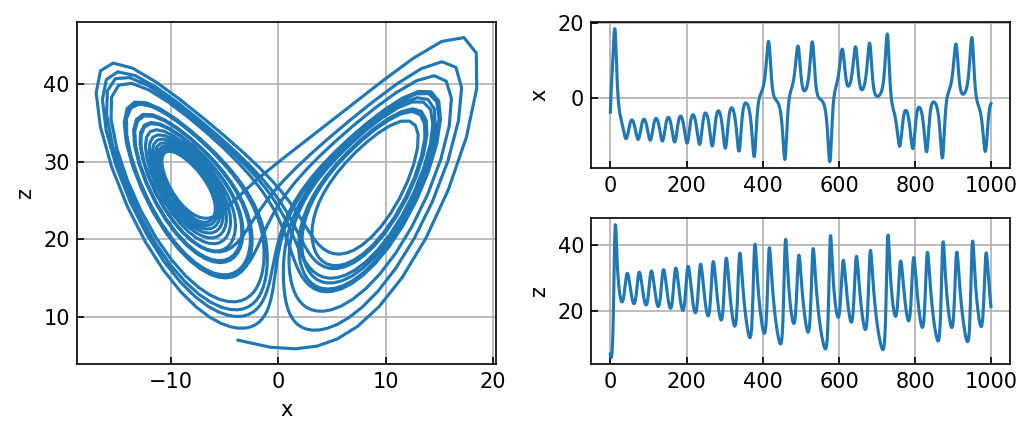

In [52]:
np.random.seed(42)
x = generate_lorenz()
print(x.shape)

fig = plt.figure(figsize=(7, 3))

ax = fig.add_subplot(121)
ax.plot(x[:, 0], x[:, 1])
ax.set(xlabel='x', ylabel='z')

ax = fig.add_subplot(222)
ax.plot(x[:, 0])
ax.set_ylabel('x')

ax = fig.add_subplot(224)
ax.plot(x[:, 1])
ax.set_ylabel('z')

plt.tight_layout()

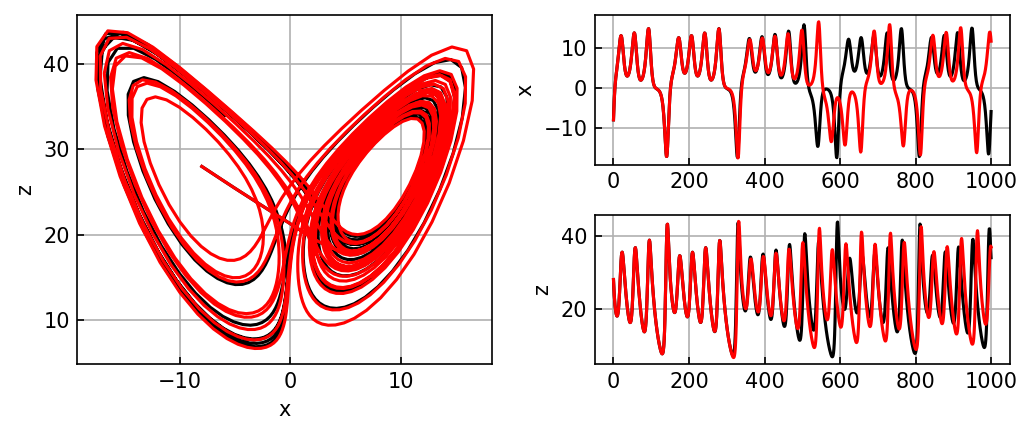

In [37]:
x0 = generate_lorenz(x0=[-8, 8, 28])
x1 = generate_lorenz(x0=[-8.001, 8.001, 28.001])

fig = plt.figure(figsize=(7, 3))

ax = fig.add_subplot(121)
ax.plot(x0[:, 0], x0[:, 1], color='black')
ax.plot(x1[:, 0], x1[:, 1], color='red')
ax.set(xlabel='x', ylabel='z')

ax = fig.add_subplot(222)
ax.plot(x0[:, 0], color='black')
ax.plot(x1[:, 0], color='red')
ax.set_ylabel('x')

ax = fig.add_subplot(224)
ax.plot(x0[:, 1], color='black')
ax.plot(x1[:, 1], color='red')
ax.set_ylabel('z')

plt.tight_layout()

MLP Train Dataset has 19980 examples
RNN Train Dataset has 19600 sequences


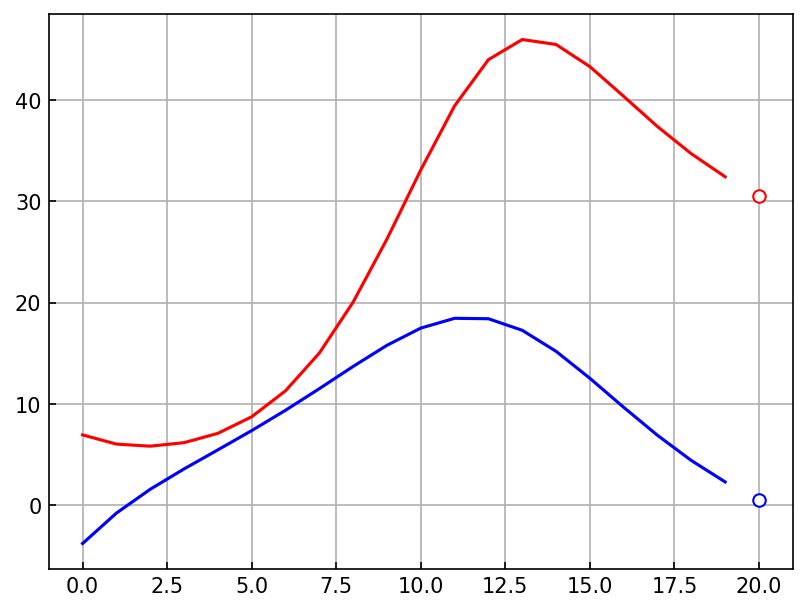

In [38]:
from torch.utils.data import Dataset, ConcatDataset

class PairDataset(Dataset):
    def __init__(self, x, seq_stride=1):
        self.x = x
        self.seq_stride = seq_stride

    def __len__(self):
        return len(self.x) - self.seq_stride

    def __getitem__(self, idx):
        """ Return the idx element of the sequence and the one after it
        """
        x = self.x[idx]
        y = self.x[idx + self.seq_stride]
        return torch.FloatTensor(x), torch.FloatTensor(y)

class SequenceDataset(Dataset):
    def __init__(self, x, seq_len=20, seq_stride=1):
        self.x = x
        self.seq_len = seq_len
        self.seq_stride = seq_stride

    def __len__(self):
        return len(self.x) - self.seq_len * self.seq_stride

    def __getitem__(self, idx):
        """ Return a sequence of length self.seq_len with stride self.seq_stride
            paired with the next element of the sequence
        """
        slc = slice(idx, idx + (self.seq_len + 1) * self.seq_stride, self.seq_stride)
        x = torch.FloatTensor(self.x[slc])
        return x[:-1], x[-1] # For each element, predict the next element in the sequence

np.random.seed(42)
train_sequences = [generate_lorenz() for i in range(20)]
val_sequences = [generate_lorenz() for i in range(4)]

mlp_train_dataset = ConcatDataset([PairDataset(seq) for seq in train_sequences])
mlp_val_dataset = ConcatDataset([PairDataset(seq) for seq in val_sequences])
print(f"MLP Train Dataset has {len(mlp_train_dataset)} examples")

rnn_train_dataset = ConcatDataset([SequenceDataset(seq) for seq in train_sequences])
rnn_val_dataset = ConcatDataset([SequenceDataset(seq) for seq in val_sequences])
print(f"RNN Train Dataset has {len(rnn_train_dataset)} sequences")

x, y = rnn_train_dataset[0]

ax = plt.figure().gca()
t = np.arange(len(x))
ax.plot(t, x[:, 0], color='blue')
ax.plot(t[-1] + 1, y[0], color='blue', marker='o', markerfacecolor='white')

ax.plot(t, x[:, 1], color='red')
ax.plot(t[-1] + 1, y[1], color='red', marker='o', markerfacecolor='white')

## Baseline: MLP

In [39]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm import trange

def train(model, optimizer, loss_func, train_dataset, val_dataset, batch_size=64, num_epochs=10, num_workers=4):
    model = model.to(device)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss = []
    train_mad = []
    val_loss = []
    val_mad = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_mad_ = 0.
        for xb, yb in train_loader:
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb)
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_mad.append(train_mad_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_mad_ = 0.
            for xb, yb in val_loader:
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb)
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
                
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_mad.append(val_mad_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_MAD=f"{train_mad[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_MAD=f"{val_mad[-1]:.3f}")
        # Consider early stopping
        # Consider learning rate scheduling

    return model, (train_loss, train_mad, val_loss, val_mad)

In [40]:
mlp_model = nn.Sequential(
    nn.Linear(2, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, 2),
)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
mlp_model, mlp_stats = train(mlp_model, optimizer, loss, mlp_train_dataset, mlp_val_dataset, num_epochs=50)

100%|██████████| 50/50 [01:49<00:00,  2.20s/it, epoch=050 / 050, train_MAD=0.272, train_loss=0.065, val_MAD=0.205, val_loss=0.057]


## RNN with Residual Structure

In [41]:
class RNN_Residual_Forecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(2, 256, num_layers=2, batch_first=True)
        self.linear = nn.Linear(256, 2)
        
    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)
        dx = self.linear(output[:, -1])
        return x[:, -1] + dx
        
res_model = RNN_Residual_Forecast().to(device)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(res_model.parameters(), lr=1e-3)
rnn_model, rnn_stats = train(res_model, optimizer, loss, rnn_train_dataset, rnn_val_dataset, num_epochs=50)

100%|██████████| 50/50 [02:18<00:00,  2.77s/it, epoch=050 / 050, train_MAD=0.012, train_loss=0.000, val_MAD=0.032, val_loss=0.001]


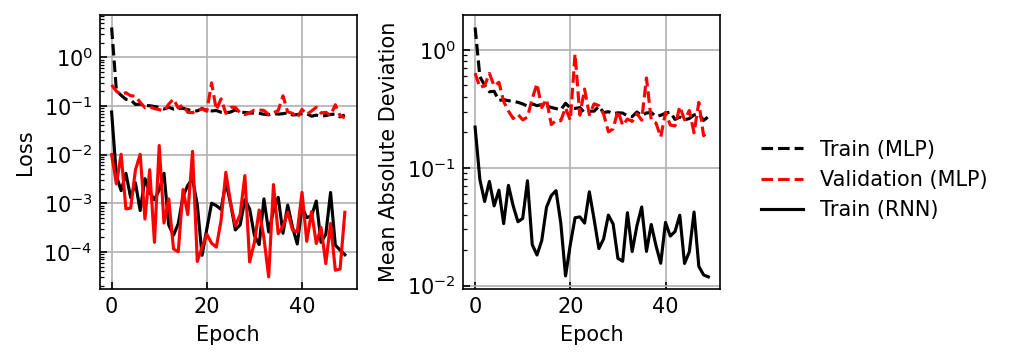

In [42]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(mlp_stats[0], color='black', linestyle='--', label='Train (MLP)')
ax[0].plot(mlp_stats[2], color='red', linestyle='--', label='Validation (MLP)')
ax[0].plot(rnn_stats[0], color='black', label='Train (RNN)')
ax[0].plot(rnn_stats[2], color='red', label='Validation (RNN)')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(mlp_stats[1], color='black', linestyle='--', label='Train (MLP)')
ax[1].plot(mlp_stats[3], color='red', linestyle='--', label='Validation (MLP)')
ax[1].plot(rnn_stats[1], color='black', label='Train (RNN)')
ax[1].set(xlabel='Epoch', ylabel='Mean Absolute Deviation', yscale='log')

fig.legend(*ax[1].get_legend_handles_labels(), 
        loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

100%|██████████| 500/500 [00:00<00:00, 9245.89it/s]


MLP Mean Absolute Error: 8.126
RNN Mean Absolute Error: 8.372


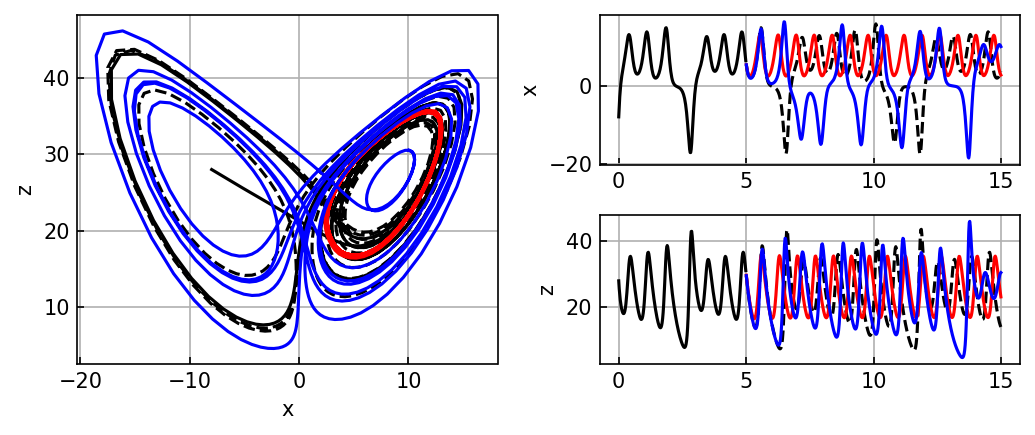

In [45]:
# Forecast second half of test sequence from first half
t_max = 15
dt = 0.02
t = np.arange(0, t_max, dt)
test = generate_lorenz(t_max=t_max, dt=dt, x0=[-8, 8, 28])
split = 250

with torch.no_grad():
    xy = torch.FloatTensor(test).to(device)
    x = xy[:split]
    y = xy[split:]

    # Forecast with MLP
    x_in = x[-1:]
    y_mlp = []
    for ii in trange(len(y)):
        y_mlp.append(mlp_model(x_in))
        x_in = y_mlp[-1]
    y_mlp = torch.concat(y_mlp, dim=0)
    print(f'MLP Mean Absolute Error: {F.l1_loss(y_mlp, y):.3f}')
    y_mlp = y_mlp.cpu().numpy()

    # Forecast with LSTM
    x_in = x[None]
    output = []
    for ii in range(len(y)):
        x_out = rnn_model(x_in)
        output.append(x_out)
        x_in = torch.concat([x_in[:, 1:], x_out[:, None]], dim=1)
        
    output = torch.stack(output, dim=1)
    y_rnn = output[0]
    print(f'RNN Mean Absolute Error: {F.l1_loss(y_rnn, y):.3f}')
    y_rnn = y_rnn.cpu().numpy()

    x = x.cpu().numpy()
    y = y.cpu().numpy()


fig = plt.figure(figsize=(7, 3))

ax = fig.add_subplot(121)
ax.plot(x[:, 0], x[:, 1], color='black')
ax.plot(y[:, 0], y[:, 1], color='black', linestyle='--')
ax.plot(y_mlp[:, 0], y_mlp[:, 1], color='red')
ax.plot(y_rnn[:, 0], y_rnn[:, 1], color='blue')
ax.set(xlabel='x', ylabel='z')

ax = fig.add_subplot(222)
ax.plot(t[:split], x[:, 0], color='black')
ax.plot(t[split:], y[:, 0], color='black', linestyle='--')
ax.plot(t[split:], y_mlp[:, 0], color='red')
ax.plot(t[split:], y_rnn[:, 0], color='blue')
ax.set_ylabel('x')

ax = fig.add_subplot(224)
ax.plot(t[:split], x[:, 1], color='black')
ax.plot(t[split:], y[:, 1], color='black', linestyle='--')
ax.plot(t[split:], y_mlp[:, 1], color='red')
ax.plot(t[split:], y_rnn[:, 1], color='blue')
ax.set_ylabel('z')

plt.tight_layout()

## KL Divergence

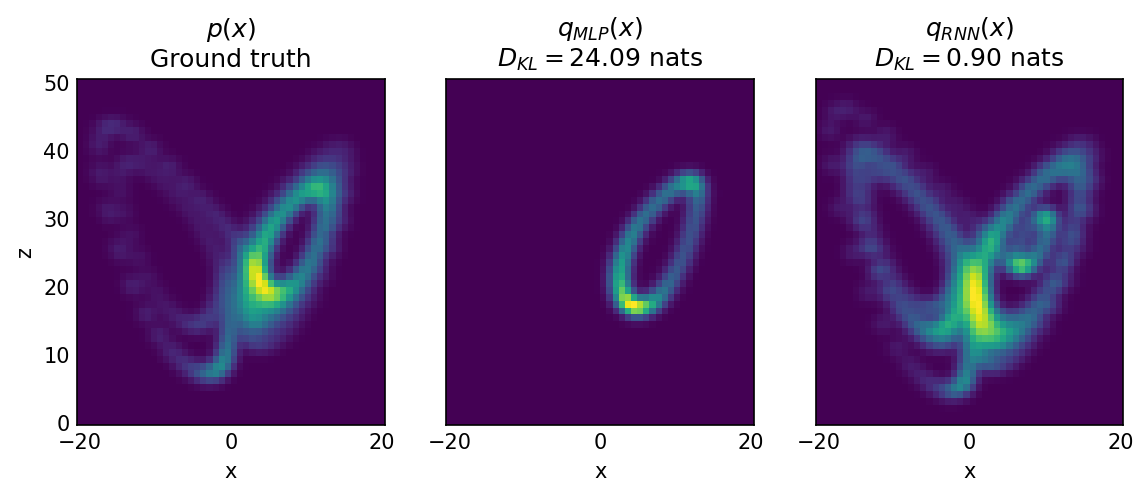

In [59]:
from sklearn.neighbors import KernelDensity

fig, ax = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)

X = np.stack(np.meshgrid(
    np.linspace(-20, 20, 50),
    np.linspace(0, 50, 50),
    indexing='xy',
), axis=-1)

base_kde = KernelDensity().fit(y)
log_p_true = base_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[0].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_true))
ax[0].set_title('$p(x)$\nGround truth')

mlp_kde = KernelDensity().fit(y_mlp)
log_p_mlp = mlp_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[1].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_mlp))

# Compute KL divergence
kld_mlp = np.sum(np.exp(log_p_true) * (log_p_true - log_p_mlp))
ax[1].set_title(f'$q_{{MLP}}(x)$\n$D_{{KL}} = {kld_mlp:.2f}$ nats')

rnn_kde = KernelDensity().fit(y_rnn)
log_p_rnn = rnn_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[2].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_rnn))

# Compute KL divergence
kld_rnn = np.sum(np.exp(log_p_true) * (log_p_true - log_p_rnn))
ax[2].set_title(f'$q_{{RNN}}(x)$\n$D_{{KL}} = {kld_rnn:.2f}$ nats')

ax[0].set_ylabel('z')
for a in ax:
    a.set_xlabel('x')

## Reservoir Computer

In [64]:
from scipy import sparse
from sklearn.linear_model import Ridge

def random_sparse_matrix(N, degree=3, spectral_radius=0.9):
    # Random symmetric, sparsely connected graph adjecency matrix
    edge_prob = degree / N
    A = np.random.rand(N, N) < edge_prob
    
    # Symmetrize the matrix
    A = np.triu(A)
    A = A + A.T

    print(np.sum(A) / np.size(A))

    # Convert to scipy sparse matrix
    A = sparse.csr_matrix(A.astype(float))

    # Compute spectral radius and rescale
    print('Rescaling reservoir', flush=True)
    max_eig = np.max(np.abs(sparse.linalg.eigs(A)[0]))

    A = A * spectral_radius / max_eig
    
    return A

class EchoStateNetwork:
    def __init__(self,
                 data_dim=1,
                 reservoir_dim=512,
                 spectral_radius=0.6,
                 avg_degree=3,
                 read_in_size=0.1,
                 l2_weight=1e-4,
                 noise=1e-3,
                 random_seed=42):
        self.data_dim = data_dim
        self.reservoir_dim = reservoir_dim
        self.spectral_radius = spectral_radius
        self.avg_degree = avg_degree
        self.l2_weight = l2_weight
        self.noise = noise

        # Initialize weights
        print('Initializing reservoir weights', flush=True)
        np.random.seed(random_seed)
        self.W_res = random_sparse_matrix(self.reservoir_dim, avg_degree, spectral_radius)

        # Initialize random input weights to the reservoir
        print('Initializing input weights')
        self.W_in = np.random.uniform(low=-read_in_size, high=read_in_size, size=[self.reservoir_dim, self.data_dim])

    def _step(self, input_state, hidden_state):
        """ Perform a reservoir update step
        """
        z = self.W_in @ input_state + self.W_res @ hidden_state
        noise = self.noise * (np.random.rand(*z.shape) - 0.5)
        return np.tanh(z) + noise

    def fit(self, X, transient=100):
        """ Fit the reservoir readout weights
            X is a sequence of size [N, d]
        """
        print('Starting to fit', flush=True)
        # Compute the hidden states at each element of the sequence
        N = X.shape[0]
        hidden_states = np.zeros([N, self.reservoir_dim])
        print('Computing hidden states', flush=True)
        for ii in range(1, N):
            hidden_states[ii, :] = self._step(X[ii-1], hidden_states[ii-1])


        print('Solving for readout weights', flush=True)
        inputs = hidden_states[transient:]
        targets = X[transient:]
        
        ridge = Ridge(alpha=self.l2_weight, fit_intercept=False).fit(inputs, targets)
        self.W_out = ridge.coef_

        # Save for continuation prediction
        self.last_out = X[-1]
        self.last_hidden = hidden_states[-1]
        
        return self
    
    def predict(self, N, input_state=None, hidden_state=None):
        """ Make a prediction given a new input
        """
        # Pick up from where we left off
        if input_state is None:
            input_state = self.last_out
        if hidden_state is None:
            hidden_state = self.last_hidden
        
        y = np.zeros([N, self.data_dim])
        for ii in range(N):
            hidden_state = self._step(input_state, hidden_state)
            y[ii] = self.W_out @ hidden_state
            input_state = y[ii]

        return y

(250, 2) (500, 2)
Initializing reservoir weights
0.00290679931640625
Rescaling reservoir
Initializing input weights
Starting to fit
Computing hidden states
Solving for readout weights
(500, 2) (500, 2)


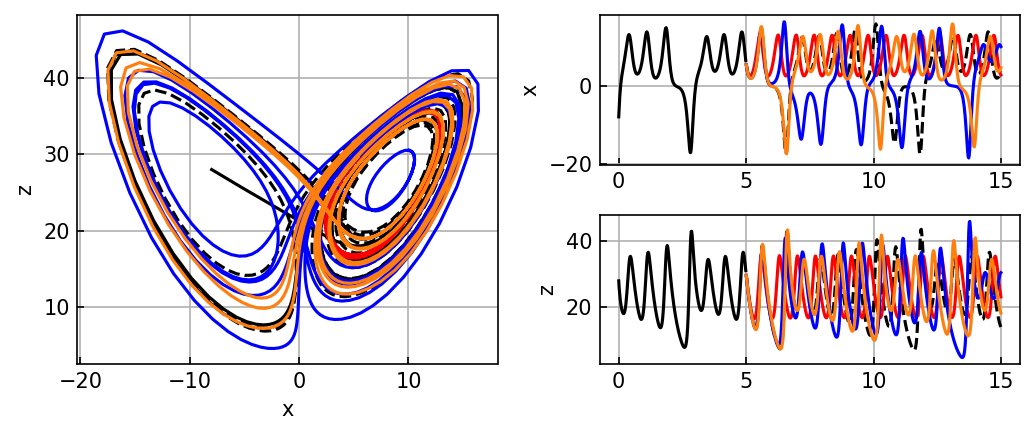

In [65]:
xy = test
x = xy[:split]
y = xy[split:]

print(x.shape, y.shape)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
esn = EchoStateNetwork(2, 1024)
esn.fit(x)
y_esn = esn.predict(len(y))

print(y.shape, y_esn.shape)

fig = plt.figure(figsize=(7, 3))

ax = fig.add_subplot(121)
ax.plot(x[:, 0], x[:, 1], color='black')
ax.plot(y[:, 0], y[:, 1], color='black', linestyle='--')
ax.plot(y_mlp[:, 0], y_mlp[:, 1], color='red')
ax.plot(y_rnn[:, 0], y_rnn[:, 1], color='blue')
ax.plot(y_esn[:, 0], y_esn[:, 1], color='tab:orange')
ax.set(xlabel='x', ylabel='z')

ax = fig.add_subplot(222)
ax.plot(t[:split], x[:, 0], color='black')
ax.plot(t[split:], y[:, 0], color='black', linestyle='--')
ax.plot(t[split:], y_mlp[:, 0], color='red')
ax.plot(t[split:], y_rnn[:, 0], color='blue')
ax.plot(t[split:], y_esn[:, 0], color='tab:orange')
ax.set_ylabel('x')

ax = fig.add_subplot(224)
ax.plot(t[:split], x[:, 1], color='black')
ax.plot(t[split:], y[:, 1], color='black', linestyle='--')
ax.plot(t[split:], y_mlp[:, 1], color='red')
ax.plot(t[split:], y_rnn[:, 1], color='blue')
ax.plot(t[split:], y_esn[:, 1], color='tab:orange')
ax.set_ylabel('z')

plt.tight_layout()

Text(0.5, 1.0, 'ESN\n$D_{KL} = 0.14$ nats')

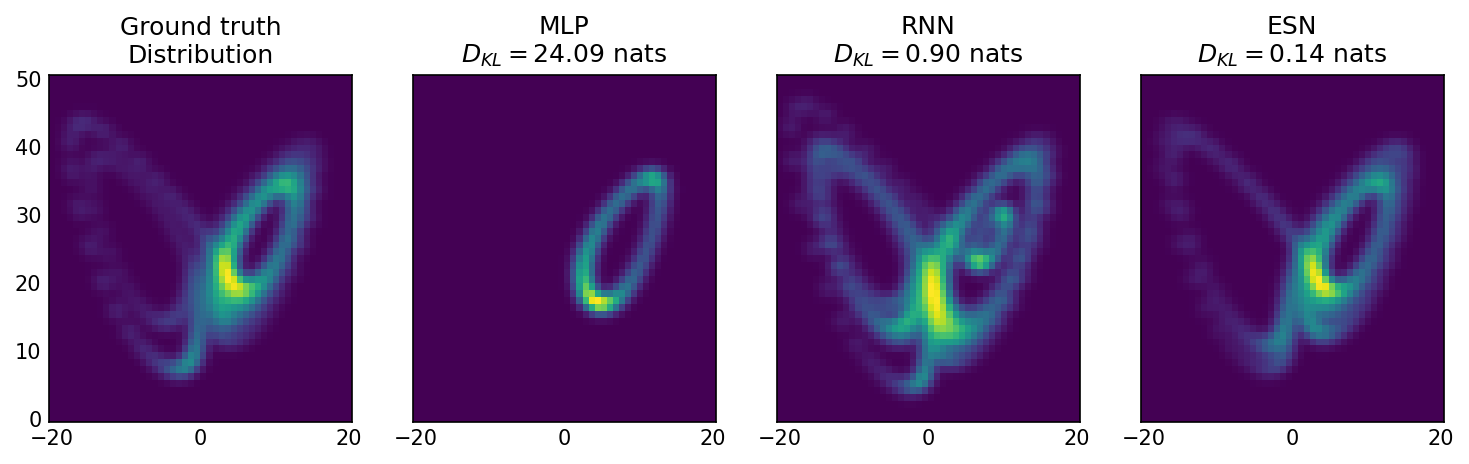

In [51]:
from sklearn.neighbors import KernelDensity

fig, ax = plt.subplots(1, 4, figsize=(12, 3), sharex=True, sharey=True)

X = np.stack(np.meshgrid(
    np.linspace(-20, 20, 50),
    np.linspace(0, 50, 50),
    indexing='xy',
), axis=-1)

base_kde = KernelDensity().fit(y)
log_p_true = base_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[0].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_true))
ax[0].set_title('Ground truth\nDistribution')

mlp_kde = KernelDensity().fit(y_mlp)
log_p_mlp = mlp_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[1].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_mlp))

# Compute KL divergence
kld_mlp = np.sum(np.exp(log_p_true) * (log_p_true - log_p_mlp))
ax[1].set_title(f'MLP\n$D_{{KL}} = {kld_mlp:.2f}$ nats')

rnn_kde = KernelDensity().fit(y_rnn)
log_p_rnn = rnn_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[2].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_rnn))

# Compute KL divergence
kld_rnn = np.sum(np.exp(log_p_true) * (log_p_true - log_p_rnn))
ax[2].set_title(f'RNN\n$D_{{KL}} = {kld_rnn:.2f}$ nats')

esn_kde = KernelDensity().fit(y_esn)
log_p_esn = esn_kde.score_samples(X.reshape([-1, 2])).reshape([50, 50])
ax[3].pcolormesh(X[:, :, 0], X[:, :, 1], np.exp(log_p_esn))

# Compute KL divergence
kld_esn = np.sum(np.exp(log_p_true) * (log_p_true - log_p_esn))
ax[3].set_title(f'ESN\n$D_{{KL}} = {kld_esn:.2f}$ nats')

## ARIMA model

/opt/conda/lib/python3.11/site-packages/statsmodels/tsa/statespace/varmax.py:161: EstimationWarning: Estimation of VARMA(p,q) models is not generically robust, due especially to identification issues.
  warn('Estimation of VARMA(p,q) models is not generically robust,'
/opt/conda/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(500, 2) (500, 2)


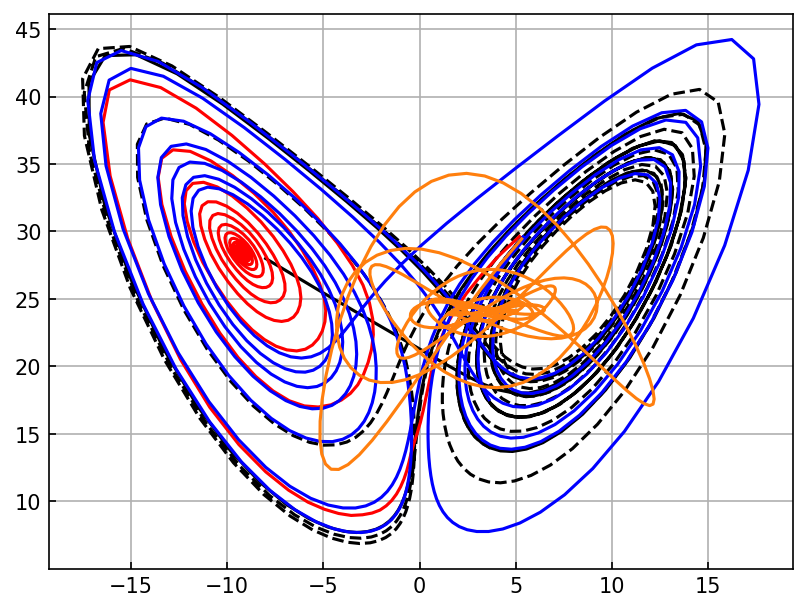

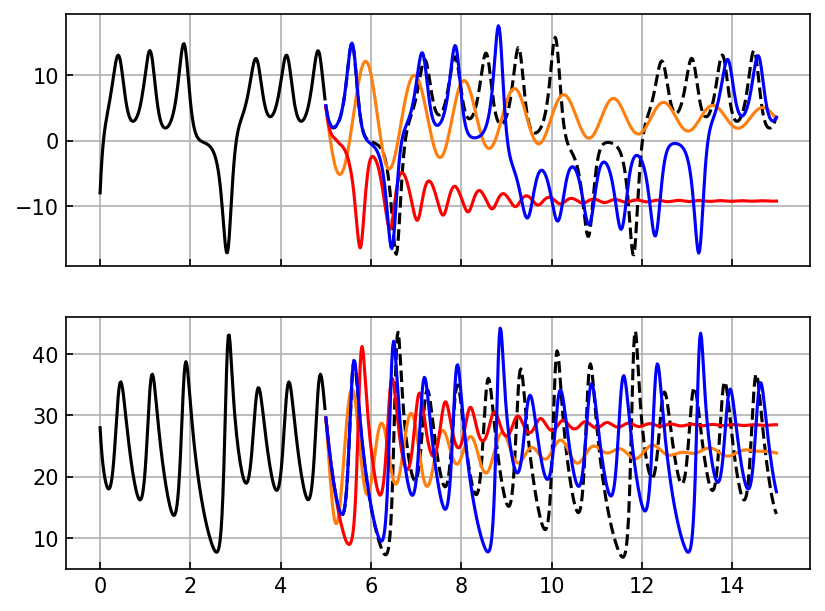

In [31]:
from statsmodels.tsa.statespace.varmax import VARMAX

xy = test[:, (0, 2)]
x = xy[:split]
y = xy[split:]

sm = VARMAX(x, order=(2, 1)).fit(disp=False)
y_sm = sm.forecast(steps=y.shape[0])

print(y.shape, y_sm.shape)


fig, ax = plt.subplots(1, 1)
ax.plot(x[:, 0], x[:, 1], color='black')
ax.plot(y[:, 0], y[:, 1], color='black', linestyle='--')
ax.plot(y_mlp[:, 0].cpu(), y_mlp[:, 1].cpu(), color='red')
ax.plot(y_rnn[:, 0].cpu(), y_rnn[:, 1].cpu(), color='blue')
ax.plot(y_sm[:, 0], y_sm[:, 1], color='tab:orange')

fig, ax = plt.subplots(2, 1, sharex=True)

for ii, a in enumerate(ax):
    a.plot(t[:split], x[:, ii], color='black')
    a.plot(t[split:], y[:, ii], color='black', linestyle='--')
    a.plot(t[split:], y_sm[:, ii], color='tab:orange')
    a.plot(t[split:], y_mlp[:, ii].cpu(), color='red')
    a.plot(t[split:], y_rnn[:, ii].cpu(), color='blue')